In [121]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

print("Libraries imported successfully!")

Libraries imported successfully!


In [122]:
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

columns = [
    "Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
    "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"
]

df = pd.read_csv(url, names=columns)

print(df.shape)
df.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [123]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [124]:
print(df.isnull().sum())

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [125]:
print((df == 0).sum())

Pregnancies                 111
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64


In [126]:
cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

df[cols] = df[cols].replace(0, np.nan)

print(df.isnull().sum())

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [127]:
df[cols] = df[cols].fillna(df[cols].median())

print(df.isnull().sum().sum())

0


In [128]:
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

print(X.shape)
print(y.shape)

(768, 8)
(768,)


In [129]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)

(614, 8) (154, 8)


In [130]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaling completed!")

Scaling completed!


In [131]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

print("KNN model trained!")

KNN model trained!


In [132]:
logistic = LogisticRegression(max_iter=1000)
logistic.fit(X_train_scaled, y_train)

print("Logistic Regression trained!")

Logistic Regression trained!


In [133]:
tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train, y_train)

print("Decision Tree trained!")

Decision Tree trained!


In [134]:
knn_pred = knn.predict(X_test_scaled)
logistic_pred = logistic.predict(X_test_scaled)
tree_pred = tree.predict(X_test)

print("Predictions completed!")

Predictions completed!


In [135]:
models = {
    "KNN": knn_pred,
    "Logistic Regression": logistic_pred,
    "Decision Tree": tree_pred
}

for name, pred in models.items():
    print("\n", name)
    print("Accuracy :", round(accuracy_score(y_test, pred), 3))
    print("Precision:", round(precision_score(y_test, pred), 3))
    print("Recall   :", round(recall_score(y_test, pred), 3))
    print("F1 Score :", round(f1_score(y_test, pred), 3))


 KNN
Accuracy : 0.753
Precision: 0.66
Recall   : 0.611
F1 Score : 0.635

 Logistic Regression
Accuracy : 0.708
Precision: 0.6
Recall   : 0.5
F1 Score : 0.545

 Decision Tree
Accuracy : 0.682
Precision: 0.553
Recall   : 0.481
F1 Score : 0.515


In [136]:
for name, pred in models.items():
    cm = confusion_matrix(y_test, pred)
    print(name)
    print(cm)
    print()

KNN
[[83 17]
 [21 33]]

Logistic Regression
[[82 18]
 [27 27]]

Decision Tree
[[79 21]
 [28 26]]



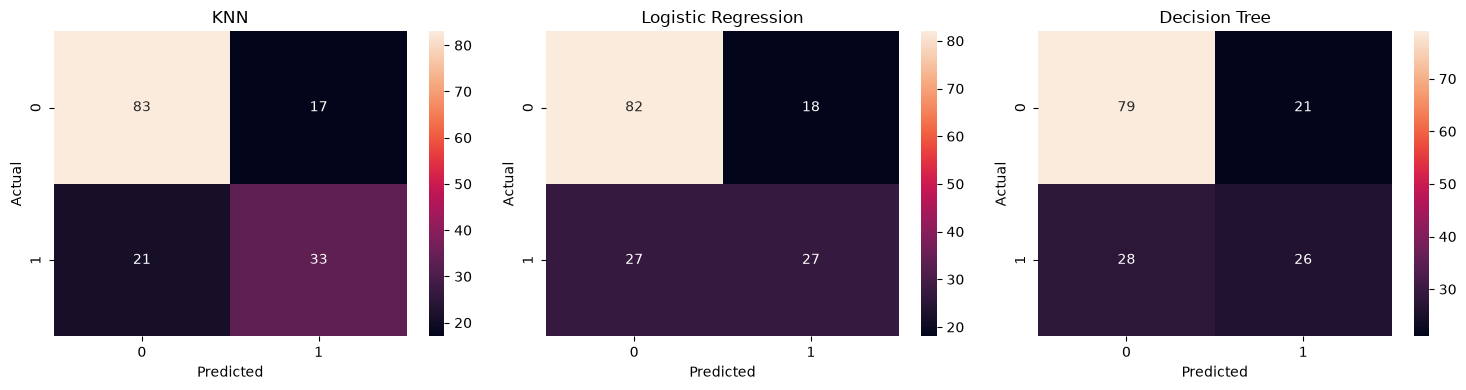

In [137]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, pred) in zip(axes, models.items()):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [138]:
knn_prob = knn.predict_proba(X_test_scaled)[:, 1]
logistic_prob = logistic.predict_proba(X_test_scaled)[:, 1]
tree_prob = tree.predict_proba(X_test)[:, 1]

print("Probabilities calculated!")

Probabilities calculated!


In [139]:
thresholds = [0.30, 0.40, 0.50, 0.60, 0.70]

for t in thresholds:
    pred = (logistic_prob >= t).astype(int)
    print(
        f"Threshold {t}: "
        f"Precision={precision_score(y_test, pred):.3f}, "
        f"Recall={recall_score(y_test, pred):.3f}, "
        f"F1={f1_score(y_test, pred):.3f}"
    )

Threshold 0.3: Precision=0.597, Recall=0.796, F1=0.683
Threshold 0.4: Precision=0.614, Recall=0.648, F1=0.631
Threshold 0.5: Precision=0.600, Recall=0.500, F1=0.545
Threshold 0.6: Precision=0.641, Recall=0.463, F1=0.538
Threshold 0.7: Precision=0.714, Recall=0.370, F1=0.488


In [140]:
results = []

for t in np.arange(0.20, 0.71, 0.05):
    pred = (logistic_prob >= t).astype(int)
    results.append([
        round(t, 2),
        precision_score(y_test, pred),
        recall_score(y_test, pred),
        f1_score(y_test, pred)
    ])

threshold_df = pd.DataFrame(
    results,
    columns=["Threshold", "Precision", "Recall", "F1"]
)

threshold_df

,Threshold,Precision,Recall,F1
0,0.20,0.551724,0.888889,0.680851
1,0.25,0.573171,0.870370,0.691176
2,0.30,0.597222,0.796296,0.682540
3,0.35,0.587302,0.685185,0.632479
4,0.40,0.614035,0.648148,0.630631
5,0.45,0.588235,0.555556,0.571429
6,0.50,0.600000,0.500000,0.545455
7,0.55,0.619048,0.481481,0.541667
8,0.60,0.641026,0.462963,0.537634
9,0.65,0.727273,0.444444,0.551724


In [141]:
threshold = 0.50

pred = (logistic_prob >= threshold).astype(int)

print("Patients flagged:", pred.sum())
print("Total patients:", len(pred))
print("Flagged percentage:", round(pred.mean() * 100, 2), "%")

Patients flagged: 45
Total patients: 154
Flagged percentage: 29.22 %


In [142]:
comparison = []

for name, pred in models.items():
    comparison.append([
        name,
        accuracy_score(y_test, pred),
        precision_score(y_test, pred),
        recall_score(y_test, pred),
        f1_score(y_test, pred)
    ])

comparison_df = pd.DataFrame(
    comparison,
    columns=["Model", "Accuracy", "Precision", "Recall", "F1"]
)

comparison_df.round(3)

,Model,Accuracy,Precision,Recall,F1
0,KNN,0.753,0.660,0.611,0.635
1,Logistic Regression,0.708,0.600,0.500,0.545
2,Decision Tree,0.682,0.553,0.481,0.515


In [143]:
best_model = comparison_df.sort_values(
    by=["Recall", "Precision"],
    ascending=False
).iloc[0]

print("Winning Model:", best_model["Model"])
print("Recall:", round(best_model["Recall"], 3))
print("Precision:", round(best_model["Precision"], 3))

Winning Model: KNN
Recall: 0.611
Precision: 0.66


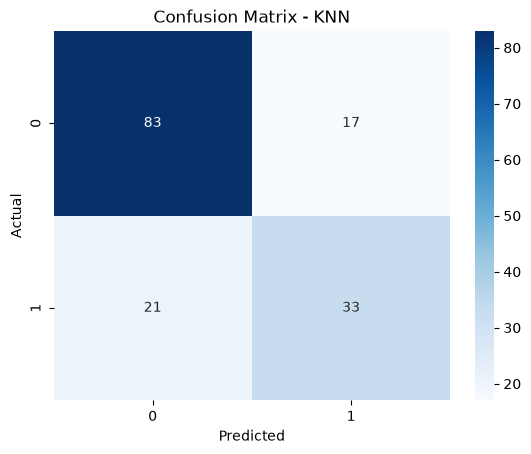

In [144]:
winner = best_model["Model"]
winner_pred = models[winner]

cm = confusion_matrix(y_test, winner_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title(f"Confusion Matrix - {winner}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [145]:
print("DIABETES RISK PREDICTION - FINAL SUMMARY")
print("-" * 45)
print("Winning Model:", winner)
print("Recall:", round(best_model["Recall"], 3))
print("Precision:", round(best_model["Precision"], 3))
print("F1 Score:", round(best_model["F1"], 3))
print("Accuracy:", round(best_model["Accuracy"], 3))
print("Clinic Capacity: 30% of patients")

DIABETES RISK PREDICTION - FINAL SUMMARY
---------------------------------------------
Winning Model: KNN
Recall: 0.611
Precision: 0.66
F1 Score: 0.635
Accuracy: 0.753
Clinic Capacity: 30% of patients


In [146]:
comparison_df.to_csv("diabetes_model_results.csv", index=False)
print("Results saved successfully!")

Results saved successfully!


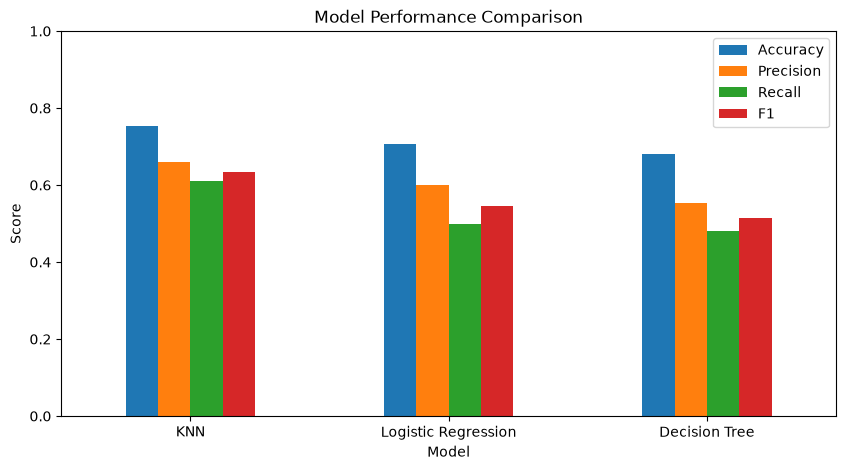

In [147]:
comparison_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1"]].plot(
    kind="bar", figsize=(10, 5)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.show()

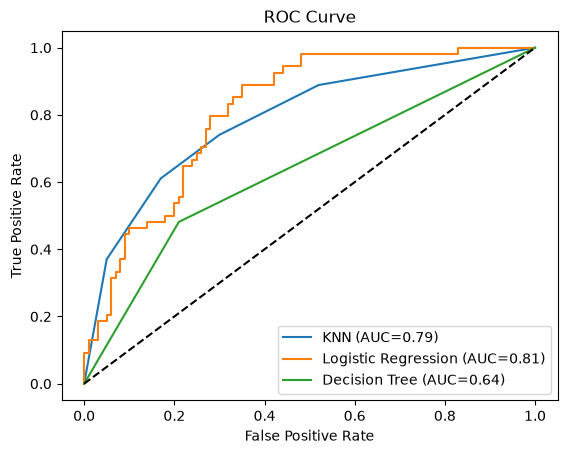

In [148]:
from sklearn.metrics import roc_curve, roc_auc_score

for name, prob in {
    "KNN": knn_prob,
    "Logistic Regression": logistic_prob,
    "Decision Tree": tree_prob
}.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, prob):.2f})")

plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

In [149]:
print("FINAL BUSINESS DECISION")
print("-" * 35)
print(f"Recommended Model: {winner}")
print(f"Recall: {best_model['Recall']:.3f}")
print(f"Precision: {best_model['Precision']:.3f}")
print("Goal: Catch as many diabetic patients as possible")
print("Clinic capacity: Maximum 30% of walk-in patients")

FINAL BUSINESS DECISION
-----------------------------------
Recommended Model: KNN
Recall: 0.611
Precision: 0.660
Goal: Catch as many diabetic patients as possible
Clinic capacity: Maximum 30% of walk-in patients


In [150]:
print("""
DIABETES RISK PREDICTION PROJECT

We trained and compared:
1. KNN
2. Logistic Regression
3. Decision Tree

Data was cleaned by replacing hidden zero values
with median values and features were standardized.

The models were evaluated using:
Accuracy, Precision, Recall, F1 Score,
and Confusion Matrix.

The winning model was selected based on
medical screening needs, especially Recall
while considering Precision.

The system is designed to help a rural clinic
prioritize patients for further diabetes testing.
""")


DIABETES RISK PREDICTION PROJECT

We trained and compared:
1. KNN
2. Logistic Regression
3. Decision Tree

Data was cleaned by replacing hidden zero values
with median values and features were standardized.

The models were evaluated using:
Accuracy, Precision, Recall, F1 Score,
and Confusion Matrix.

The winning model was selected based on
medical screening needs, especially Recall
while considering Precision.

The system is designed to help a rural clinic
prioritize patients for further diabetes testing.

